# Data

In [14]:
if AE_FeatureExtract == 1:
    X_final_train, y_final_train, _,_ = build_feature_embedding_matrix(model, train_loader)
    X_final_val, y_final_val, _,_ = build_feature_embedding_matrix(model, val_loader)
    X_final_test, y_final_test, _,_ = build_feature_embedding_matrix(model, test_loader)

    print(X_final_train.shape)
    
if AE_FeatureExtract == 0:        
    X_final_train = X_train[:,-1,:]
    y_final_train = y_train
    X_final_val = X_val[:,-1,:]
    y_final_val = y_val
    X_final_test = X_test[:,-1,:]
    y_final_test = y_test
    
    print(X_final_train.shape)
    print(y_final_train.shape)
    
    

(50912, 240)


# TabPFN

In [15]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

from tabpfn import TabPFNClassifier

model_file = "../data/TabPFN_weights/tabpfn-v2.6-classifier-v2.6_default.ckpt"

classifier = TabPFNClassifier(
    model_path=model_file,          # local checkpoint or 'auto'
    device=DEV,
    n_estimators=16,                # more ensembles → better accuracy
    softmax_temperature=0.9,        # default, lower = sharper predictions
    balance_probabilities=True,     # useful for imbalanced 5-class data
    fit_mode='fit_preprocessors',   # good balance of speed vs memory
    inference_precision='autocast', # faster GPU inference
    random_state=42
)

In [16]:

classifier.fit(X_final_train, y_final_train)

y_eval = classifier.predict(X_final_test)


/data/home/majid/.local/lib/python3.9/site-packages/torch/cuda/__init__.py:61: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]


TabPFN Accuracy: 0.7788
              precision    recall  f1-score   support

           0     0.9378    0.8376    0.8849      8982
           1     0.5631    0.6871    0.6190      3273
           2     0.6308    0.6706    0.6501      1712
           3     0.4957    0.6609    0.5665       348
           4     0.6948    0.7698    0.7304       139

    accuracy                         0.7788     14454
   macro avg     0.6644    0.7252    0.6901     14454
weighted avg     0.8036    0.7788    0.7877     14454



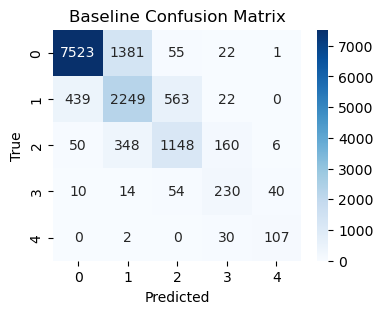

In [18]:
from tqdm import tqdm
from sklearn.metrics import f1_score, accuracy_score
import matplotlib.pyplot as plt
import seaborn as sns


acc = accuracy_score(y_final_test, y_eval)
f1_macro = f1_score(y_final_test, y_eval, average="macro", zero_division=0)
TabPFN_results = np.array([f1_macro, acc])

# 5. Results
print(f"TabPFN Accuracy: {acc :.4f}")
print(classification_report(y_final_test, y_eval, digits=4))

cm = confusion_matrix(y_final_test, y_eval)

plt.figure(figsize=(4,3))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")

plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Baseline Confusion Matrix")

plt.show()